In [1]:
!pip install langgraph langchain-anthropic

In [2]:
# 예시 데이터
%%writefile notes.txt
17
3
57
7
34

Overwriting notes.txt


In [9]:
def calculator(a: float, op: str, b: float) -> str:
    OPS = {"+": lambda x, y: x + y, "-": lambda x, y: x - y,
           "*": lambda x, y: x * y, "/": lambda x, y: x / y}
    if op not in OPS:
        return "오류: 지원하지 않는 연산자"
    if op == "/" and b == 0:
        return "오류: 0으로 나눌 수 없음"
    return str(OPS[op](a, b))

def read_file(path: str) -> str:
    try:
        with open(path, encoding="utf-8") as f:
            return f.read()
    except FileNotFoundError:
        return f"오류: {path} 파일이 없음"

tools = [
    {
        "name": "calculator",
        "description": "두 수를 연산(사칙연산). 모든 사칙 연산에는 이 툴을 반드시 사용한다.",
        "input_schema": {
            "type": "object",
            "properties": {
                            "a": {"type": "number"},
                            "op": {"type": "string", "enum":["+","-","*","/"]},
                            "b": {"type": "number"}
                        },
            "required": ["a", "op", "b"],
        }
    },
    {
        "name": "read_file",
        "description": "파일을 읽음",
        "input_schema": {
            "type": "object",
            "properties": {"path":{"type":"string"}},
            "required": ["path"],
        }
    }
]   # 단원 0의 tools 리스트 그대로 붙여넣기
TOOL_FUNCS = {"calculator": calculator, "read_file": read_file}

In [10]:
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph.message import add_messages

class State(TypedDict):
    messages: Annotated[list, add_messages]
    last_call: tuple | None

In [11]:
import os
from google.colab import userdata
from langchain_anthropic import ChatAnthropic
from langchain_core.messages import ToolMessage
from langgraph.graph import END

os.environ["ANTHROPIC_API_KEY"] = userdata.get("ANTHROPIC_API_KEY")
model = ChatAnthropic(model="claude-sonnet-5-5").bind_tools(tools)

def agent(state: State):
    response = model.invoke(state["messages"])
    return {"messages": [response]}

def route(state: State):
    if state["messages"][-1].tool_calls:
        return "tools"
    return END

def tools_node(state: State):
    last = state["messages"][-1]
    results = []
    for call in last.tool_calls:
        output = TOOL_FUNCS[call["name"]](**call["args"])
        results.append(ToolMessage(content=str(output), tool_call_id=call["id"]))
    return {"messages": results}

In [12]:
from langgraph.graph import StateGraph, START

builder = StateGraph(State)
builder.add_node("agent", agent)
builder.add_node("tools", tools_node)

builder.add_edge(START, "agent")                 # 화살표 1
builder.add_conditional_edges("agent", route)    # 화살표 2, 3 (route가 tools / END 중 고름)
builder.add_edge("tools", "agent")                   # 화살표 4

graph = builder.compile()

In [13]:
result = graph.invoke({
    "messages": [{"role": "user", "content": "notes.txt 파일을 읽고 안쪽의 숫자들을 모두 더해줘. 툴을 되도록 사용해줘"}],
    "last_call": None,
})

for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

notes.txt 파일을 읽고 안쪽의 숫자들을 모두 더해줘. 툴을 되도록 사용해줘
================================== Ai Message ==================================

[{'id': 'toolu_01K3xSPPfxztJTgUqDawri9p', 'caller': {'type': 'direct'}, 'input': {'path': 'notes.txt'}, 'name': 'read_file', 'type': 'tool_use', 'toolset_name': None}]
Tool Calls:
  read_file (toolu_01K3xSPPfxztJTgUqDawri9p)
 Call ID: toolu_01K3xSPPfxztJTgUqDawri9p
  Args:
    path: notes.txt
================================= Tool Message =================================

17
3
57
7
34

================================== Ai Message ==================================

[{'signature': 'CAQSpAYKEAgUGAI4AUIIdGhpbmtpbmcSDEt99WcfrV08MiGl8BoMIWtzJmFSTmrrva+IIjDJtYaZsCpImqj4NDZTfDITzISgdSHlb+/fvrNs2absgjKPnpiOJ1h/VaBSDhdepdIqwQX/Y8XunIr8I81McNP7awMq0fOCOAk0ZQDkQTadj3ZyPGTN9Q9oFSKaXH3bHhrGiU6eGMk/W1Jf/ab3wy4BtJGuQKJysthUfJqW7/vHONYz77epoVYNsEa0F/AGydRpVbItS4Nagn7iTkg1nF90SF+Kr1KGj3btmzxhfw

# 실습 3번 - 루프 스택 바꾸기

In [19]:
class State(TypedDict):
    messages: Annotated[list, add_messages]
    last_call: tuple | None
    step_count: int

MAX_STEPS = 2

def agent(state: State):
    response = model.invoke(state["messages"])
    return {"messages": [response],
            "step_count": state["step_count"] + 1}   # 올리기: 노드에서

def limit_node(state: State):
    last = state["messages"][-1]
    results = [ToolMessage(content="반복 제한으로 실행하지 않음",
                           tool_call_id=call["id"])
               for call in last.tool_calls]
    return {"messages": results}

def route(state: State):
    has_calls = bool(state["messages"][-1].tool_calls)
    if state["step_count"] >= MAX_STEPS:             # 검사: router에서
        return "limit" if has_calls else END   # 짝이 없을 때만 정리하러
    return "tools" if has_calls else END


In [23]:
# 위 파트에서 limit 추가

from langgraph.graph import StateGraph, START

builder = StateGraph(State)
builder.add_node("agent", agent)
builder.add_node("tools", tools_node)
builder.add_node("limit", limit_node)

builder.add_edge(START, "agent")                 # 화살표 1
builder.add_conditional_edges("agent", route, ["tools", "limit", END])    # 화살표 2, 3 (route가 tools / END 중 고름)
builder.add_edge("tools", "agent")                   # 화살표 4
builder.add_edge("limit", END)

graph = builder.compile()

In [16]:
result = graph.invoke({
    "messages": [{"role": "user", "content": "notes.txt 파일을 읽고 안쪽의 숫자들을 모두 더해줘. 툴을 되도록 사용해줘"}],
    "last_call": None,
    "step_count": 0,
})


for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

notes.txt 파일을 읽고 안쪽의 숫자들을 모두 더해줘. 툴을 되도록 사용해줘
================================== Ai Message ==================================

[{'id': 'toolu_01Kvr33TXRb9JWiRqdBi5Pgx', 'caller': {'type': 'direct'}, 'input': {'path': 'notes.txt'}, 'name': 'read_file', 'type': 'tool_use', 'toolset_name': None}]
Tool Calls:
  read_file (toolu_01Kvr33TXRb9JWiRqdBi5Pgx)
 Call ID: toolu_01Kvr33TXRb9JWiRqdBi5Pgx
  Args:
    path: notes.txt
================================= Tool Message =================================

17
3
57
7
34

================================== Ai Message ==================================

[{'signature': 'CAQSmwYKEAgUGAI4AUIIdGhpbmtpbmcSDCJbUwXG2oqfdExXWhoMy7B3S+eEh1BbUIrbIjCc2YDnjPDf3Unw/ECm0OQMpLSg/9sHv3rnhCEVFPzZFlDYnlyfehcURcn2QKlWom8quAWGZHZV/v3HdH7rxLOgWsusbN0Ny3TIrJ2ipzEF9swh9KD8mOGSlqSuvPLpWNoWXhiCtMPIll/6m+uwj6FJhQMfd9VghAw+lP/5RjS5QlsNsi5XwrBixQmfibaqHxQMzDhyLYOmU6z21rvkgbWeu66L/+j8t2qwfseNro

# 실습 4번

In [24]:
print(graph.get_graph().draw_mermaid())                 # Mermaid 텍스트

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	agent(agent)
	tools(tools)
	limit(limit)
	__end__([<p>__end__</p>]):::last
	__start__ --> agent;
	agent -.-> __end__;
	agent -.-> limit;
	agent -.-> tools;
	tools --> agent;
	limit --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



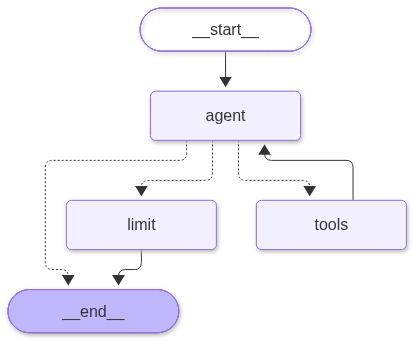

In [25]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))    # 그림으로 보기